# OptiQ: Entrenamiento y Calibracion de la PINN para QAOA (v4 - Con K-Fold CV y Normalizacion de Loss)

Este notebook implementa el pipeline completo de la **Physics-Informed Neural Network (PINN)** para OptiQ:
1. **Preprocesamiento Unificado (17 Features):** 11 métricas espectrales/topológicas + 6 categorías de `problem_type` (One-Hot).
2. **Arquitectura con Quantum Jittering:** Inyección de ruido estocástico controlado en entrenamiento (sigma=0.015).
3. **Pérdida Normalizada con Simetría Cuántica (`QuantumSymmetricLoss`):** Reconoce periodicidad modulo-pi en beta y promedia entre los 6 ángulos para escala de Loss comparable (~0.27).
4. **Stratified 5-Fold Cross Validation:** Valida rigurosamente la capacidad de generalización calculando MAE = media +- std.
5. **Entrenamiento Final y Model Checkpointing:** Entrena con tracking del mejor checkpoint (`best_val_loss`).
6. **Exportación Portable:** Guarda `weights/pinn_qaoa_weights.pt` y `weights/pinn_metadata.json` listos para inferencia en el backend.

In [61]:
import os
import json
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Fijar semillas para reproducibilidad total
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo de computo para entrenamiento: {device}')

Dispositivo de computo para entrenamiento: cpu


## 1. Carga y Codificación de Variables (17 Features)
Cargamos las 10,000 instancias del dataset e incorporamos las variables de familia de problema.

In [62]:
dataset_path = '../dataset/qaoa_pignn_dataset.csv'
df = pd.read_csv(dataset_path)

num_feature_cols = [
    'num_qubits_n', 'num_couplings_m', 'graph_density',
    'spectral_gap_lambda2', 'spectral_radius_lambda_max', 'global_frustration_index',
    'h_mean', 'h_std', 'J_mean', 'J_std', 'optimal_penalty_lambda'
]

df_encoded = pd.get_dummies(df, columns=['problem_type'], dtype=np.float32)
cat_cols = [c for c in df_encoded.columns if c.startswith('problem_type_')]
all_feature_cols = num_feature_cols + cat_cols

target_angles_cols = [
    'gamma_p1_0', 'beta_p1_0',
    'gamma_p2_0', 'gamma_p2_1', 'beta_p2_0', 'beta_p2_1'
]
target_telemetry_cols = ['recommended_shots', 'recommended_lr_eta', 'target_depth_p_star']

X = df_encoded[all_feature_cols].values.astype(np.float32)
Y_angles = df_encoded[target_angles_cols].values.astype(np.float32)
Y_telemetry = df_encoded[target_telemetry_cols].values.astype(np.float32)
problem_labels = df['problem_type'].values

print(f'Dataset cargado: {X.shape[0]} instancias con {X.shape[1]} features de entrada.')

Dataset cargado: 10000 instancias con 17 features de entrada.


## 2. Arquitectura del Modelo: `QaoaPINN`
Incluye bloque de inyección de ruido estocástico (`GaussianJitter`) activo en entrenamiento y backbone residual profundo.

In [63]:
class GaussianJitter(nn.Module):
    def __init__(self, std=0.015):
        super().__init__()
        self.std = std
        
    def forward(self, x):
        if self.training:
            # Solo perturbamos las primeras 11 features continuas
            noise = torch.randn_like(x[:, :11]) * self.std
            continuous_jittered = x[:, :11] + noise
            return torch.cat([continuous_jittered, x[:, 11:]], dim=1)
        return x

class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim, dropout=0.05):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim)
        )
        self.act = nn.GELU()
        
    def forward(self, x):
        return self.act(x + self.block(x))

class QaoaPINN(nn.Module):
    def __init__(self, in_features=17, hidden_dim=128):
        super().__init__()
        self.jitter = GaussianJitter(std=0.015)
        self.input_layer = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU()
        )
        self.res1 = ResidualBlock(hidden_dim, dropout=0.05)
        self.res2 = ResidualBlock(hidden_dim, dropout=0.05)
        
        # Head 1: Angulos QAOA (6 salidas)
        self.angles_head = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.GELU(),
            nn.Linear(64, 6)
        )
        
        # Head 2: Telemetria (shots, lr, p_star)
        self.telemetry_head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.GELU(),
            nn.Linear(32, 3)
        )
        
    def forward(self, x):
        x_noisy = self.jitter(x)
        feat = self.input_layer(x_noisy)
        feat = self.res1(feat)
        feat = self.res2(feat)
        angles = self.angles_head(feat)
        telemetry = self.telemetry_head(feat)
        return angles, telemetry

## 3. Función de Pérdida con Simetría Cuántica Normalizada (`QuantumSymmetricLoss`)
Promedia el error entre los 6 ángulos para que la escala de Loss sea directamente comparable con SmoothL1 puro (~0.27).

In [64]:
class QuantumSymmetricLoss(nn.Module):
    def __init__(self, lambda_adiab=0.01, lambda_bound=0.005):
        super().__init__()
        self.loss_gamma = nn.SmoothL1Loss(beta=0.1, reduction='none')
        self.lambda_adiab = lambda_adiab
        self.lambda_bound = lambda_bound
        
    def forward(self, pred, target):
        gamma_indices = [0, 2, 3]
        beta_indices  = [1, 4, 5]
        
        # 1. Error de fase para gammas
        l_gamma_elem = self.loss_gamma(pred[:, gamma_indices], target[:, gamma_indices])
        
        # 2. Error periodico modulo pi para betas (equivalencia cuantica de compuertas)
        diff_direct = torch.abs(pred[:, beta_indices] - target[:, beta_indices])
        diff_minus_pi = torch.abs(pred[:, beta_indices] - (target[:, beta_indices] - np.pi))
        diff_plus_pi  = torch.abs(pred[:, beta_indices] - (target[:, beta_indices] + np.pi))
        min_beta_diff = torch.minimum(diff_direct, torch.minimum(diff_minus_pi, diff_plus_pi))
        
        l_beta_elem = torch.where(min_beta_diff < 0.1, 0.5 * (min_beta_diff ** 2) / 0.1, min_beta_diff - 0.05)
        
        # Promedio normalizado entre los 6 angulos
        l_data = (l_gamma_elem.sum(dim=1) + l_beta_elem.sum(dim=1)).mean() / 6.0
        
        # 3. Consistencia adiabatica suave para beta en p=2 (beta_0 >= beta_1)
        beta_0 = pred[:, 4]
        beta_1 = pred[:, 5]
        l_adiab = torch.relu(beta_1 - beta_0).mean()
        
        # 4. Regularizacion de frontera periodica [-pi, 2*pi]
        lower_viol = torch.relu(-pred - np.pi).mean()
        upper_viol = torch.relu(pred - (2.0 * np.pi)).mean()
        l_bound = lower_viol + upper_viol
        
        total_loss = l_data + self.lambda_adiab * l_adiab + self.lambda_bound * l_bound
        return total_loss, l_data, l_adiab

def compute_physical_mae(pred, target):
    """Calcula el MAE angular reconociendo la simetria de fase modulo-pi en beta."""
    gamma_indices = [0, 2, 3]
    beta_indices  = [1, 4, 5]
    diff_gamma = torch.abs(pred[:, gamma_indices] - target[:, gamma_indices])
    
    d_dir = torch.abs(pred[:, beta_indices] - target[:, beta_indices])
    d_min = torch.abs(pred[:, beta_indices] - (target[:, beta_indices] - np.pi))
    d_pls = torch.abs(pred[:, beta_indices] - (target[:, beta_indices] + np.pi))
    diff_beta = torch.minimum(d_dir, torch.minimum(d_min, d_pls))
    
    total_diff = diff_gamma.sum() + diff_beta.sum()
    return (total_diff / (pred.shape[0] * 6)).item()

## 4. Stratified 5-Fold Cross Validation (Validación Cruzada)
Comprobamos la estabilidad y ausencia de sesgo entrenando en 5 pliegues estratificados por familia de problema.

In [65]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []
k_epochs = 15
batch_size = 64

print('=== Ejecutando Stratified 5-Fold Cross Validation (15 epocas por fold) ===')
for fold, (train_idx, val_idx) in enumerate(skf.split(X, problem_labels), 1):
    # Normalizar continuo para evitar leakage
    x_tr_fold = X[train_idx].copy()
    x_va_fold = X[val_idx].copy()
    y_tr_fold = Y_angles[train_idx]
    y_va_fold = Y_angles[val_idx]
    
    fold_scaler = StandardScaler()
    x_tr_fold[:, :11] = fold_scaler.fit_transform(x_tr_fold[:, :11])
    x_va_fold[:, :11] = fold_scaler.transform(x_va_fold[:, :11])
    
    tr_loader = DataLoader(TensorDataset(torch.tensor(x_tr_fold), torch.tensor(y_tr_fold)), batch_size=batch_size, shuffle=True)
    va_loader = DataLoader(TensorDataset(torch.tensor(x_va_fold), torch.tensor(y_va_fold)), batch_size=batch_size, shuffle=False)
    
    fold_model = QaoaPINN(in_features=17).to(device)
    fold_crit = QuantumSymmetricLoss()
    fold_opt = optim.AdamW(fold_model.parameters(), lr=2e-3, weight_decay=1e-4)
    fold_sched = optim.lr_scheduler.CosineAnnealingLR(fold_opt, T_max=k_epochs, eta_min=1e-5)
    
    for ep in range(k_epochs):
        fold_model.train()
        for bx, by in tr_loader:
            bx, by = bx.to(device), by.to(device)
            fold_opt.zero_grad()
            pred, _ = fold_model(bx)
            loss, _, _ = fold_crit(pred, by)
            loss.backward()
            fold_opt.step()
        fold_sched.step()
        
    # Evaluacion del fold
    fold_model.eval()
    va_mae_list = []
    with torch.no_grad():
        for bx, by in va_loader:
            bx, by = bx.to(device), by.to(device)
            pred, _ = fold_model(bx)
            va_mae_list.append(compute_physical_mae(pred, by) * bx.size(0))
    fold_mae = sum(va_mae_list) / len(x_va_fold)
    cv_results.append(fold_mae)
    print(f'Fold {fold}/5 - Val MAE Fisico: {fold_mae:.4f} rad')

print(f'\n>>> Rendimiento General Cross-Validation: {np.mean(cv_results):.4f} +- {np.std(cv_results):.4f} rad <<<')

=== Ejecutando Stratified 5-Fold Cross Validation (15 epocas por fold) ===
Fold 1/5 - Val MAE Fisico: 0.3031 rad
Fold 2/5 - Val MAE Fisico: 0.3008 rad
Fold 3/5 - Val MAE Fisico: 0.3108 rad
Fold 4/5 - Val MAE Fisico: 0.3036 rad
Fold 5/5 - Val MAE Fisico: 0.3001 rad

>>> Rendimiento General Cross-Validation: 0.3037 +- 0.0038 rad <<<


## 5. Entrenamiento Final Completo con Model Checkpointing (40 Épocas)
Entrenamiento definitivo con split 80/10/10 guardando el mejor estado (`best_val_loss`).

In [66]:
# Split Train / Val / Test (80/10/10) estratificado por familia de problema
X_train, X_temp, Y_ang_train, Y_ang_temp, lbl_train, lbl_temp = train_test_split(
    X, Y_angles, problem_labels, test_size=0.20, random_state=42, stratify=problem_labels
)
X_val, X_test, Y_ang_val, Y_ang_test = train_test_split(
    X_temp, Y_ang_temp, test_size=0.50, random_state=42, stratify=lbl_temp
)

# Ajuste de scaler unicamente en Train
scaler_X = StandardScaler()
X_train[:, :11] = scaler_X.fit_transform(X_train[:, :11])
X_val[:, :11]   = scaler_X.transform(X_val[:, :11])
X_test[:, :11]  = scaler_X.transform(X_test[:, :11])

train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(Y_ang_train)), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(torch.tensor(X_val), torch.tensor(Y_ang_val)), batch_size=64, shuffle=False)

model = QaoaPINN(in_features=17).to(device)
criterion = QuantumSymmetricLoss(lambda_adiab=0.01, lambda_bound=0.005)
optimizer = optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40, eta_min=1e-5)

epochs = 40
best_val_loss = float('inf')
best_model_weights = None
history = {'train_loss': [], 'val_loss': [], 'val_mae': []}

print('Iniciando entrenamiento final optimizado...')
for epoch in range(1, epochs + 1):
    model.train()
    tr_loss = 0.0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        pred, _ = model(bx)
        loss, _, _ = criterion(pred, by)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * bx.size(0)
    scheduler.step()
    
    # Validacion
    model.eval()
    va_loss, va_mae = 0.0, 0.0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            pred, _ = model(bx)
            loss, _, _ = criterion(pred, by)
            va_loss += loss.item() * bx.size(0)
            va_mae  += compute_physical_mae(pred, by) * bx.size(0)
            
    epoch_tr_loss = tr_loss / len(X_train)
    epoch_va_loss = va_loss / len(X_val)
    epoch_va_mae  = va_mae / len(X_val)
    
    history['train_loss'].append(epoch_tr_loss)
    history['val_loss'].append(epoch_va_loss)
    history['val_mae'].append(epoch_va_mae)
    
    # Model Checkpoint
    if epoch_va_loss < best_val_loss:
        best_val_loss = epoch_va_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        
    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch [{epoch:02d}/{epochs:02d}] - Train Loss: {epoch_tr_loss:.5f} | Val Loss: {epoch_va_loss:.5f} | Val MAE Fisico: {epoch_va_mae:.4f} rad')

# Cargar el mejor estado al finalizar
model.load_state_dict(best_model_weights)
print(f'Entrenamiento finalizado. Mejor Val Loss cargado: {best_val_loss:.5f}')


Iniciando entrenamiento final optimizado...
Epoch [01/40] - Train Loss: 0.32886 | Val Loss: 0.31155 | Val MAE Fisico: 0.3476 rad
Epoch [05/40] - Train Loss: 0.28622 | Val Loss: 0.29413 | Val MAE Fisico: 0.3282 rad
Epoch [10/40] - Train Loss: 0.28071 | Val Loss: 0.29100 | Val MAE Fisico: 0.3243 rad
Epoch [15/40] - Train Loss: 0.27484 | Val Loss: 0.28749 | Val MAE Fisico: 0.3198 rad
Epoch [20/40] - Train Loss: 0.27282 | Val Loss: 0.28348 | Val MAE Fisico: 0.3159 rad
Epoch [25/40] - Train Loss: 0.27018 | Val Loss: 0.28179 | Val MAE Fisico: 0.3138 rad
Epoch [30/40] - Train Loss: 0.26787 | Val Loss: 0.28071 | Val MAE Fisico: 0.3119 rad
Epoch [35/40] - Train Loss: 0.26568 | Val Loss: 0.27935 | Val MAE Fisico: 0.3099 rad
Epoch [40/40] - Train Loss: 0.26512 | Val Loss: 0.27905 | Val MAE Fisico: 0.3095 rad
Entrenamiento finalizado. Mejor Val Loss cargado: 0.27876


## 6. Curvas de Convergencia

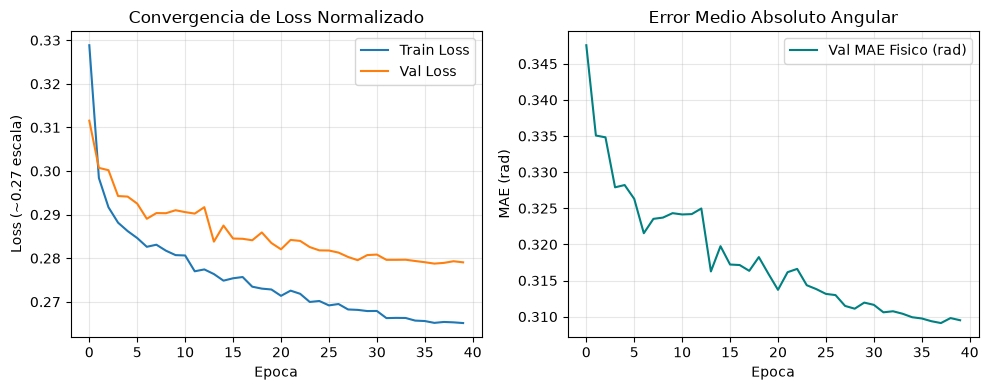

In [67]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.title('Convergencia de Loss Normalizado')
plt.xlabel('Epoca')
plt.ylabel('Loss (~0.27 escala)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history['val_mae'], color='teal', label='Val MAE Fisico (rad)')
plt.title('Error Medio Absoluto Angular')
plt.xlabel('Epoca')
plt.ylabel('MAE (rad)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Exportación Portable de Checkpoints

In [68]:
weights_dir = 'weights'
os.makedirs(weights_dir, exist_ok=True)

# 1. Guardar el mejor estado del modelo
weights_path = os.path.join(weights_dir, 'pinn_qaoa_weights.pt')
torch.save(model.state_dict(), weights_path)
print(f'Mejores pesos exportados en: {weights_path} ({os.path.getsize(weights_path)/1024:.1f} KB)')

# 2. Exportar metadatos para despliegue sin scikit-learn
metadata = {
    'continuous_features': num_feature_cols,
    'categorical_features': cat_cols,
    'scaler_mean': scaler_X.mean_.tolist(),
    'scaler_scale': scaler_X.scale_.tolist(),
    'target_angles': target_angles_cols
}
meta_path = os.path.join(weights_dir, 'pinn_metadata.json')
with open(meta_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)
print(f'Metadatos de produccion exportados en: {meta_path}')

Mejores pesos exportados en: weights\pinn_qaoa_weights.pt (341.7 KB)
Metadatos de produccion exportados en: weights\pinn_metadata.json


## 8. Verificación e Inferencia Unitaria en Test Set

In [69]:
sample_x = torch.tensor(X_test[:1], dtype=torch.float32).to(device)
model.eval()
with torch.no_grad():
    pred_angles, _ = model(sample_x)
    pred_np = pred_angles.cpu().numpy()[0]
    true_np = Y_ang_test[0]

print('Verificacion Muestra de Prueba (Pred vs Real):')
for name, p_val, t_val in zip(target_angles_cols, pred_np, true_np):
    if 'beta' in name:
        # Distancia periodica modulo pi
        err = min(abs(p_val - t_val), abs(p_val - (t_val - np.pi)), abs(p_val - (t_val + np.pi)))
    else:
        err = abs(p_val - t_val)
    print(f'  {name:<12}: Pred = {p_val:+.4f} | Real = {t_val:+.4f} | Error Fisico = {err:.4f} rad')

Verificacion Muestra de Prueba (Pred vs Real):
  gamma_p1_0  : Pred = +0.4844 | Real = +0.4961 | Error Fisico = 0.0117 rad
  beta_p1_0   : Pred = +0.7784 | Real = +0.7598 | Error Fisico = 0.0186 rad
  gamma_p2_0  : Pred = +0.8405 | Real = +1.1879 | Error Fisico = 0.3474 rad
  gamma_p2_1  : Pred = +0.4185 | Real = +0.4381 | Error Fisico = 0.0196 rad
  beta_p2_0   : Pred = +0.8966 | Real = +0.8031 | Error Fisico = 0.0935 rad
  beta_p2_1   : Pred = +0.8968 | Real = +1.5428 | Error Fisico = 0.6460 rad
